In [183]:
import pandas as pd

In [184]:
## Welcome to Laura's python notebook! Laura is a master's student at CUNY Journalism School. 
## She's into science, health, and making sure powerful people and systems are being held accountable. 
## We're going to dig into NYC's latest manhole fire data, to see if we spot new trends. Join us. 

In [185]:
# An important note for Lam: Laura and Ambra looked into manholes last semester. 
## We did not follow the data cleaning steps or create a readme file etc. I am using the same data source, 
## but creating a fresh analysis with updated numbers and different steps. I am using calendar year in addition to fiscal year (like we did last time).

## Import a copy of the filtered dataset from NYC Open Data. You can find the original dataset here: 
## https://data.cityofnewyork.us/Public-Safety/Fire-Incident-Dispatch-Data/8m42-w767/explore/query/SELECT%0A%20%20%60starfire_incident_id%60%2C%0A%20%20%60incident_datetime%60%2C%0A%20%20%60alarm_box_location%60%2C%0A%20%20%60incident_borough%60%2C%0A%20%20%60zipcode%60%2C%0A%20%20%60incident_classification%60%2C%0A%20%20%60incident_classification_group%60%2C%0A%20%20%60first_assignment_datetime%60%2C%0A%20%20%60first_activation_datetime%60%2C%0A%20%20%60first_on_scene_datetime%60%2C%0A%20%20%60incident_close_datetime%60%0AWHERE%0A%20%20%60incident_datetime%60%0A%20%20%20%20BETWEEN%20%222019-07-01T18%3A18%3A23%22%20%3A%3A%20floating_timestamp%0A%20%20%20%20AND%20%222026-10-30T18%3A18%3A23%22%20%3A%3A%20floating_timestamp%0ASEARCH%20%22manhole%22/page/filter
## This dataset was last updated on October 5, 2026 and was provided to NYC Open Data
## by the Fire Department of New York City (FDNY). 

dfmanhole = pd.read_csv(
    "../data/Fire_Incident_Dispatch_Data_20261030.csv"
)  

## LP note to self: .. means parent directory. In this case, manhole-2026 

In [186]:
## Now let's get comfortable with the data! 
# We'll start by poking around and looking at the columns and contents. 

dfmanhole.info()

<class 'pandas.DataFrame'>
RangeIndex: 26731 entries, 0 to 26730
Data columns (total 11 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   STARFIRE_INCIDENT_ID           26731 non-null  str    
 1   INCIDENT_DATETIME              26731 non-null  str    
 2   ALARM_BOX_LOCATION             26730 non-null  str    
 3   INCIDENT_BOROUGH               26731 non-null  str    
 4   ZIPCODE                        26335 non-null  float64
 5   INCIDENT_CLASSIFICATION        26731 non-null  str    
 6   INCIDENT_CLASSIFICATION_GROUP  26731 non-null  str    
 7   FIRST_ASSIGNMENT_DATETIME      26479 non-null  str    
 8   FIRST_ACTIVATION_DATETIME      26449 non-null  str    
 9   FIRST_ON_SCENE_DATETIME        25982 non-null  str    
 10  INCIDENT_CLOSE_DATETIME        26729 non-null  str    
dtypes: float64(1), str(10)
memory usage: 2.2 MB


In [187]:
## Let's look at the number of rows
dfmanhole.shape

(26731, 11)

In [188]:
## This means we have 11 columns and 26,731 rows. 
## I'm realizing for this analysis, I probably won't use columns 7-10. 
## So I will drop them using the drop function.

dfmanhole = dfmanhole.drop(
    columns=["FIRST_ASSIGNMENT_DATETIME", "FIRST_ACTIVATION_DATETIME", "FIRST_ON_SCENE_DATETIME", "INCIDENT_CLOSE_DATETIME"]
)


In [189]:
## Let's look at the data frame again to make sure the columns were dropped.
dfmanhole.info()


<class 'pandas.DataFrame'>
RangeIndex: 26731 entries, 0 to 26730
Data columns (total 7 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   STARFIRE_INCIDENT_ID           26731 non-null  str    
 1   INCIDENT_DATETIME              26731 non-null  str    
 2   ALARM_BOX_LOCATION             26730 non-null  str    
 3   INCIDENT_BOROUGH               26731 non-null  str    
 4   ZIPCODE                        26335 non-null  float64
 5   INCIDENT_CLASSIFICATION        26731 non-null  str    
 6   INCIDENT_CLASSIFICATION_GROUP  26731 non-null  str    
dtypes: float64(1), str(6)
memory usage: 1.4 MB


In [190]:
print(dfmanhole.head(20))

     STARFIRE_INCIDENT_ID       INCIDENT_DATETIME  \
0   240101-B1440-002-1018  01/01/2024 07:38:53 PM   
1   240103-M0577-002-1065  01/03/2024 06:47:13 PM   
2        1918260710150792  07/01/2019 08:35:49 PM   
3        1918207110141313  07/01/2019 10:02:44 PM   
4        1918303250110014  07/02/2019 12:10:57 AM   
5        1918324980140057  07/02/2019 12:43:03 AM   
6        1918306580110662  07/02/2019 11:20:15 AM   
7        1918351540150297  07/02/2019 11:31:43 AM   
8        1918309110240570  07/02/2019 01:12:41 PM   
9        1918353660150717  07/02/2019 08:55:29 PM   
10       1918391920150920  07/02/2019 10:19:51 PM   
11       1918407790140098  07/03/2019 03:44:45 AM   
12       1918467080150079  07/03/2019 04:49:01 AM   
13       1918403610130061  07/03/2019 09:59:09 AM   
14       1918488460150494  07/03/2019 02:09:07 PM   
15       1918442110150540  07/03/2019 02:57:42 PM   
16       1918410330140818  07/03/2019 05:27:39 PM   
17       1918415250111301  07/03/2019 06:45:29

In [191]:
## Awesome! 
## I want to make sure the INCIDENT_DATETIME column is a recognized date type.

dfmanhole["INCIDENT_DATETIME"] = pd.to_datetime(
    dfmanhole["INCIDENT_DATETIME"],
    format="%m/%d/%Y %I:%M:%S %p",
    errors="raise"
)


In [192]:

print(dfmanhole["INCIDENT_DATETIME"].dtype)

datetime64[us]


In [193]:
## This means it's in a readable date format. 

In [194]:
print(dfmanhole["INCIDENT_DATETIME"].head())

0   2024-01-01 19:38:53
1   2024-01-03 18:47:13
2   2019-07-01 20:35:49
3   2019-07-01 22:02:44
4   2019-07-02 00:10:57
Name: INCIDENT_DATETIME, dtype: datetime64[us]


In [195]:
dfmanhole.info()


<class 'pandas.DataFrame'>
RangeIndex: 26731 entries, 0 to 26730
Data columns (total 7 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   STARFIRE_INCIDENT_ID           26731 non-null  str           
 1   INCIDENT_DATETIME              26731 non-null  datetime64[us]
 2   ALARM_BOX_LOCATION             26730 non-null  str           
 3   INCIDENT_BOROUGH               26731 non-null  str           
 4   ZIPCODE                        26335 non-null  float64       
 5   INCIDENT_CLASSIFICATION        26731 non-null  str           
 6   INCIDENT_CLASSIFICATION_GROUP  26731 non-null  str           
dtypes: datetime64[us](1), float64(1), str(5)
memory usage: 1.4 MB


In [196]:
## Let's look at a sample of the data:
dfmanhole.head(10)

,STARFIRE_INCIDENT_ID,INCIDENT_DATETIME,ALARM_BOX_LOCATION,INCIDENT_BOROUGH,ZIPCODE,INCIDENT_CLASSIFICATION,INCIDENT_CLASSIFICATION_GROUP
0,240101-B1440-002-1018,2024-01-01 19:38:53,4 AVE & 28 ST,BROOKLYN,11232.0,Manhole Fire - Other,NonStructural Fires
1,240103-M0577-002-1065,2024-01-03 18:47:13,BROADWAY & E 17 ST,MANHATTAN,10003.0,Manhole Fire - Seeping Smoke,NonStructural Fires
2,1918260710150792,2019-07-01 20:35:49,ATLANTIC AVE & 127 ST,QUEENS,11419.0,Manhole Fire - Other,NonStructural Fires
3,1918207110141313,2019-07-01 22:02:44,BUSHWICK AVE & DEKALB AVE,BROOKLYN,11221.0,Manhole Fire - Seeping Smoke,NonStructural Fires
4,1918303250110014,2019-07-02 00:10:57,VARICK ST & SPRING ST,MANHATTAN,10013.0,Manhole Fire - Other,NonStructural Fires
5,1918324980140057,2019-07-02 00:43:03,PARKVILLE AVE & EAST 8 ST,BROOKLYN,11230.0,Manhole Fire - Seeping Smoke,NonStructural Fires
6,1918306580110662,2019-07-02 11:20:15,9 AVE & W 28 ST,MANHATTAN,10001.0,Manhole Fire - Blown Cover,NonStructural Fires
7,1918351540150297,2019-07-02 11:31:43,DORAN AVE & 88 ST,QUEENS,11385.0,Manhole Fire - Blown Cover,NonStructural Fires
8,1918309110240570,2019-07-02 13:12:41,KINGSTON AVE & PACIFIC ST,BROOKLYN,11216.0,Manhole Fire - Other,NonStructural Fires
9,1918353660150717,2019-07-02 20:55:29,LINDEN BLVD & 193 ST,QUEENS,11412.0,Manhole Fire - Other,NonStructural Fires


In [197]:
## This is looking good! Now let's clean things up. 
## I want my Zipcode to be a string, not a float. Because the zipcode isn't a tally, it's an identifier.
# I also want to make sure that the Zipcode is 5 digits.

dfmanhole["ZIPCODE"] = dfmanhole["ZIPCODE"].astype("string")



In [198]:
## Now I want to see which columns have missing values. I will use the isnull() function and sum() to get a count of missing values in each column.
## I scanned this old Quartz article to better undertand data cleaning issues: https://gijn.org/stories/the-quartz-guide-to-bad-data/


In [199]:
## Let's see how many data points are missing.
print(dfmanhole.isnull().sum())


STARFIRE_INCIDENT_ID               0
INCIDENT_DATETIME                  0
ALARM_BOX_LOCATION                 1
INCIDENT_BOROUGH                   0
ZIPCODE                          396
INCIDENT_CLASSIFICATION            0
INCIDENT_CLASSIFICATION_GROUP      0
dtype: int64


In [200]:
## This is great! Now let's check the percentage of missing data.
print(dfmanhole.isnull().mean() * 100)


STARFIRE_INCIDENT_ID             0.000000
INCIDENT_DATETIME                0.000000
ALARM_BOX_LOCATION               0.003741
INCIDENT_BOROUGH                 0.000000
ZIPCODE                          1.481426
INCIDENT_CLASSIFICATION          0.000000
INCIDENT_CLASSIFICATION_GROUP    0.000000
dtype: float64


In [201]:
## This seems great. Not a huge percentage of missing data.

## Next let's look for other potential data issues. 
## I want to better understand the STARFIRE_INCIDENT_ID column. I'll look at the data dictionary. 
## I downloaded the data dictionary here: https://data.cityofnewyork.us/Public-Safety/Fire-Incident-Dispatch-Data/8m42-w767/about_data
# I learned that the STARFIRE_INCIDENT_ID is a unique identifier "comprising the 5 character  julian date, 4 character alarm box number, 2 character number of incidents at the box so far for the day, 1 character borough code , 4 character sequence number.""
# So there should be no duplicates in that column.
# Let's check for duplicated in that column. 


In [202]:
## Check if any rows are fully duplicated. 
dfmanhole.duplicated().any()

np.False_

In [203]:
## Show any duplicate rows.
dfmanhole[dfmanhole.duplicated(keep=False)]

,STARFIRE_INCIDENT_ID,INCIDENT_DATETIME,ALARM_BOX_LOCATION,INCIDENT_BOROUGH,ZIPCODE,INCIDENT_CLASSIFICATION,INCIDENT_CLASSIFICATION_GROUP


In [204]:
## Check for duplicates in a certain column. 

dfmanhole[dfmanhole.duplicated(subset=["STARFIRE_INCIDENT_ID"], keep=False)]

,STARFIRE_INCIDENT_ID,INCIDENT_DATETIME,ALARM_BOX_LOCATION,INCIDENT_BOROUGH,ZIPCODE,INCIDENT_CLASSIFICATION,INCIDENT_CLASSIFICATION_GROUP


In [205]:
dfmanhole.duplicated().sum()

np.int64(0)

In [206]:
## This is great! We have no repeated values. 

# Now let's analyse. 

## We want to know how many incidents there were in the past few years by year. Hopefully we will spot a trend.
## An important element to consider is there could be multiple logged incidents that stem from the same fire. 
## BUT we will rely on the STARFIRE_INCIDENT_ID to identify unique incidents as counted by the FDNY.
## And an idea! Let's plot it after in plotly and by zipcode. AND let's use the fivethirtyeight template to make it kinda pretty.  


In [207]:
## Copilot prompt: show how many total incidents per calendar year. Then for NYC fiscal year. 

# Make sure the column is a date
dfmanhole["INCIDENT_DATETIME"] = pd.to_datetime(
    dfmanhole["INCIDENT_DATETIME"],
    errors="raise"
)

In [209]:
# Calendar year: January 1–December 31
calendar_year = (
    dfmanhole["INCIDENT_DATETIME"]
    .dt.year
    .value_counts()
    .sort_index()
)

print(calendar_year)

INCIDENT_DATETIME
2019    1639
2020    3246
2021    4799
2022    3625
2023    1297
2024    2856
2025    4385
2026    4884
Name: count, dtype: int64


In [210]:
## Great, we found something new that hasn't been reported! 
## There were more manhole fire incidents recorded in 2026 than in the past 7 years. 
## Let's also take a look at the NYC fiscal year: July 1–June 30.

fiscal_year = (
    dfmanhole["INCIDENT_DATETIME"]
    .dt.to_period("Y-JUN")
    .value_counts()
    .sort_index()
)

print(fiscal_year)


INCIDENT_DATETIME
2020    2581
2021    6104
2022    3758
2023    1539
2024    2734
2025    3531
2026    5768
2027     716
Freq: Y-JUN, Name: count, dtype: int64


In [211]:
## Holy moly. That's a lot of incidents in fiscal 2026. Definitely worth reporting.
## Now the question is, do we go with regular year or fiscal year? For now, we'll do both.


In [212]:
## Copilot prompt: Show incidents by month. 

incidents_by_month = (
    dfmanhole["INCIDENT_DATETIME"]
    .dt.to_period("M")
    .value_counts()
    .sort_index()
)

print(incidents_by_month)

INCIDENT_DATETIME
2019-07    482
2019-08    139
2019-09    129
2019-10    124
2019-11     96
          ... 
2026-05    211
2026-06    197
2026-07    373
2026-08    226
2026-09    117
Freq: M, Name: count, Length: 87, dtype: int64


In [213]:
## Copilot prompt: Show incidents by month as a total tally for all years. 

incidents_by_month = (
    dfmanhole["INCIDENT_DATETIME"]
    .dt.month_name()
    .value_counts()
    .reindex([
        "January", "February", "March", "April",
        "May", "June", "July", "August",
        "September", "October", "November", "December"
    ])
)

print(incidents_by_month)

INCIDENT_DATETIME
January      4253
February     8346
March        1575
April         784
May           934
June         1345
July         2243
August       1492
September    1155
October       597
November      474
December     3533
Name: count, dtype: int64


In [223]:
## Let's remember that this does NOT include the Nov + Dec 2026
## This shows us that most incidents seem to happen in February.

## Let's plot! I will create a fivethirtyeight-style plot using Plotly. 

!pip install matplotlib

import matplotlib.pyplot as plt

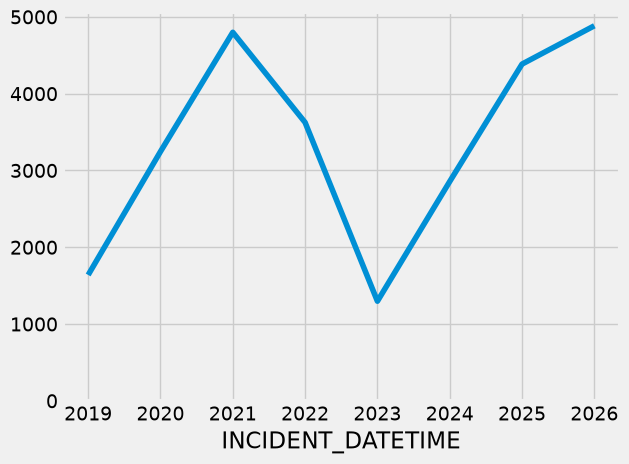

In [224]:
ax = calendar_year.plot(
    x="calendar_year",
    y="manhole fires"
)

ax.set_ylim(bottom=0)
plt.show()

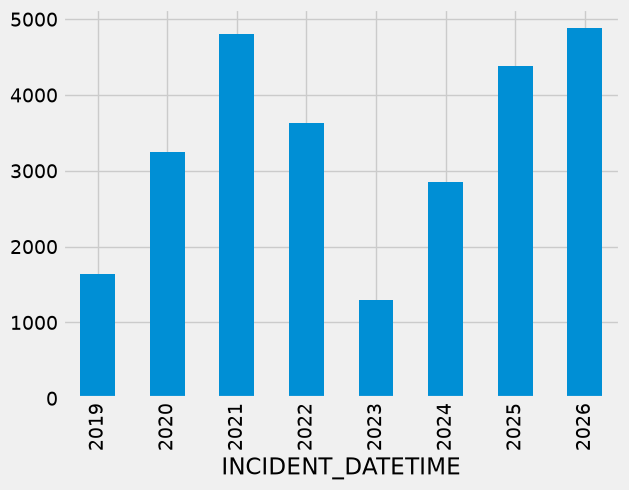

In [225]:
## Wow, that is ugly. Let's make a bar chart instead.
ax = calendar_year.plot(kind="bar", x="calendar_year", y="manhole fires")
ax.set_ylim(bottom=0)
plt.show()

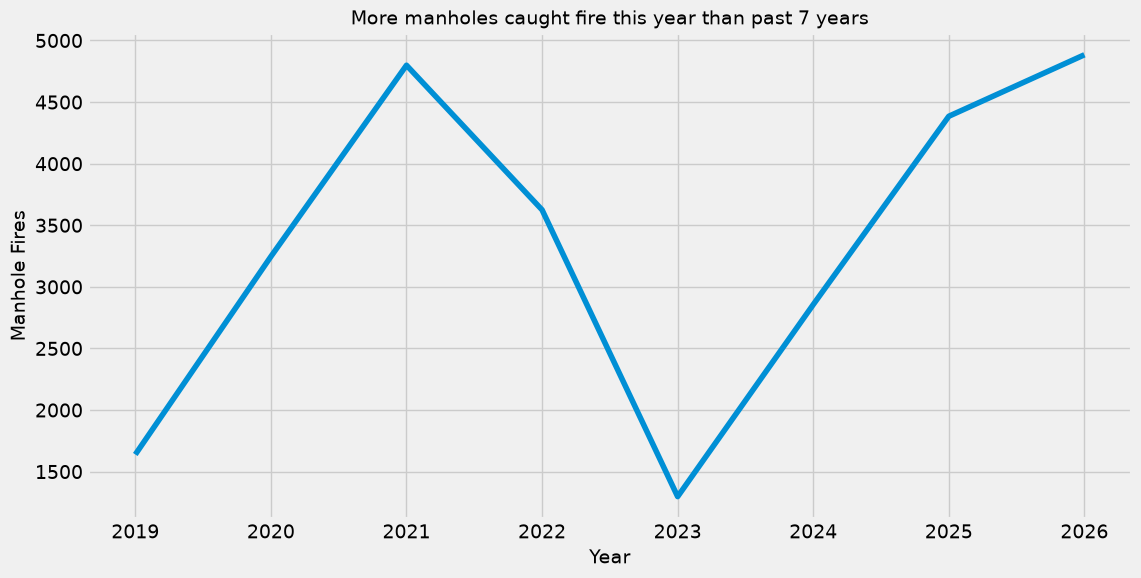

In [239]:
## Much better. Now let's polish it. 
style = 'fivethirtyeight'
fig, ax = plt.subplots(figsize=(12, 6))
## Start every chart with 12 and 6 size. This is a good size for a chart.
## Fig is the wide square
## Ax = is the canvas. This is where the chart will be drawn. (I.e. it sets the margins)
ax.plot(calendar_year)
ax.set_xlabel('Year', fontsize=14)
ax.set_ylabel('Manhole Fires', fontsize=14)
ax.set_title('More manholes caught fire this year than past 7 years', fontsize=14)

output_folder = Path("output")
output_folder.mkdir(exist_ok=True)

fig.savefig(
    output_folder / "manhole_fires_by_year.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [240]:
incidents_by_year_month = (
    dfmanhole["INCIDENT_DATETIME"]
    .dt.to_period("M")
    .value_counts()
    .sort_values(ascending=False)
    .head(10)
)

print(incidents_by_year_month)

INCIDENT_DATETIME
2021-02    2785
2026-02    2163
2020-12    1370
2025-02    1299
2022-02    1154
2025-12     960
2022-01     953
2026-01     949
2024-01     872
2025-01     791
Freq: M, Name: count, dtype: int64


In [241]:
from pathlib import Path

output_folder = Path("output")
output_folder.mkdir(exist_ok=True)

# Save the pared-down dataframe
dfmanhole.to_csv(
    output_folder / "dfmanhole_cleaned.csv",
    index=False
)